# **Regresión Lineal**

El *análisis de la regresión* es un proceso estadístico para estimar las relaciones entre variables. Se puede implementar para estudiar la relación entre una variable dependiente (o variable respuesta) $y$ y una o más variables independientes (variables regresoras o predictoras) $x_1,x_2,...,x_n$ a través de una ecuación lineal.

En este rubro, se distinguen dos modalidades:

1) Regresión Lineal Simple:
 * Cuando se emplean únicamente dos variables: $x$, $y$

2) Regresión Lineal Multiple:
 * Cuando se tienen más de dos variables: $x_1,x_2,...,x_n,y$

La ecuación de regresión lineal es:

$$ \widehat{y}  = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n + \epsilon$$

donde:
* $\widehat{y}$: variable dependiente o respuesta.
* $n$: número de variables predictoras.
* $x_i$: *i-ésima* variable independiente o predictora.
* $\theta_j$: coeficientes de regresión ($\theta_0$ corresponde al intercepto y $\theta_1, \theta_2,...,\theta_n$ corresponden a los pesos asociados a las variables predictoras).
* $\epsilon$: error.

# Regresión lineal simple: Índice de masa corporal

Utilizaremos un *dataframe* de datos corporales para predecir el peso de una persona dado su índice de masa corporal.

Para ello, seguiremos la siguiente metodología:

* Análisis exploratorio de las variables elegidas para el modelo.
* Obtención de la ecuación de regresión
* Predicción de datos

#**Cargar librerías**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns

Cargar archivo BodyData.csv

In [4]:
df = pd.read_csv("BodyData.csv",encoding ="latin-1")
df

,AGE,GENDER (1=M),PULSE,SYSTOLIC,DIASTOLIC,HDL,LDL,WHITE,RED,PLATE,WEIGHT,HEIGHT,WAIST,ARM CIRC,BMI
0,43,0,80,100,70,73,68,8.7,4.80,319,98.6,172.0,120.4,40.7,33.3
1,57,1,84,112,70,35,116,4.9,4.73,187,96.9,186.0,107.8,37.0,28.0
2,38,0,94,134,94,36,223,6.9,4.47,297,108.2,154.4,120.3,44.3,45.4
3,80,1,74,126,64,37,83,7.5,4.32,170,73.1,160.5,97.2,30.3,28.4
4,34,1,50,114,68,50,104,6.1,4.95,140,83.1,179.0,95.1,34.0,25.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,24,1,94,96,62,43,102,7.0,5.29,260,56.3,162.7,78.4,27.9,21.3
296,50,0,94,132,84,42,69,7.9,4.35,244,103.2,146.7,142.6,39.5,48.0
297,53,1,86,132,74,42,112,8.4,4.07,75,102.6,181.0,117.7,36.5,31.3
298,34,0,74,104,54,44,103,7.6,4.36,292,96.1,162.2,109.0,37.0,36.5


Información general del conjunto de datos

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   AGE           300 non-null    int64  
 1   GENDER (1=M)  300 non-null    int64  
 2   PULSE         300 non-null    int64  
 3   SYSTOLIC      300 non-null    int64  
 4   DIASTOLIC     300 non-null    int64  
 5   HDL           300 non-null    int64  
 6   LDL           300 non-null    int64  
 7   WHITE         300 non-null    float64
 8   RED           300 non-null    float64
 9   PLATE         300 non-null    int64  
 10  WEIGHT        300 non-null    float64
 11  HEIGHT        300 non-null    float64
 12  WAIST         300 non-null    float64
 13  ARM CIRC      300 non-null    float64
 14  BMI           300 non-null    float64
dtypes: float64(7), int64(8)
memory usage: 35.2 KB


## Análisis rápido

Columnas del df

In [7]:
df.columns

Index(['AGE', 'GENDER (1=M)', 'PULSE', 'SYSTOLIC', 'DIASTOLIC', 'HDL', 'LDL',
       'WHITE', 'RED', 'PLATE', 'WEIGHT', 'HEIGHT', 'WAIST', 'ARM CIRC',
       'BMI'],
      dtype='str')

Descripción estadística

In [8]:
df.describe

<bound method NDFrame.describe of      AGE  GENDER (1=M)  PULSE  SYSTOLIC  DIASTOLIC  HDL  LDL  WHITE   RED  \
0     43             0     80       100         70   73   68    8.7  4.80   
1     57             1     84       112         70   35  116    4.9  4.73   
2     38             0     94       134         94   36  223    6.9  4.47   
3     80             1     74       126         64   37   83    7.5  4.32   
4     34             1     50       114         68   50  104    6.1  4.95   
..   ...           ...    ...       ...        ...  ...  ...    ...   ...   
295   24             1     94        96         62   43  102    7.0  5.29   
296   50             0     94       132         84   42   69    7.9  4.35   
297   53             1     86       132         74   42  112    8.4  4.07   
298   34             0     74       104         54   44  103    7.6  4.36   
299   31             1     90       104         70   64  112    6.0  5.07   

     PLATE  WEIGHT  HEIGHT  WAIST  ARM CI

## Revisamos si existen valores vacíos o duplicados

<Axes: >

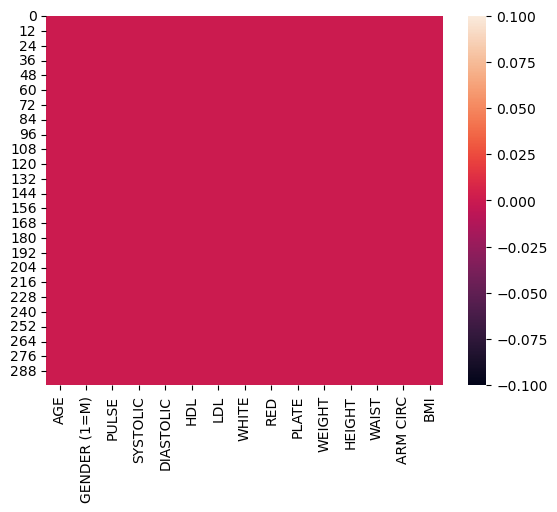

In [16]:
#Creamos un mapa de calor para identificar visualmente los atributos que tienen registros vacíos
sns.heatmap(df.isnull())

In [14]:
df.isnull().sum()

AGE             0
GENDER (1=M)    0
PULSE           0
SYSTOLIC        0
DIASTOLIC       0
HDL             0
LDL             0
WHITE           0
RED             0
PLATE           0
WEIGHT          0
HEIGHT          0
WAIST           0
ARM CIRC        0
BMI             0
dtype: int64

In [ ]:
# Revisar si existen duplicados


## Análisis de correlación

In [15]:
df.corr()

,AGE,GENDER (1=M),PULSE,SYSTOLIC,DIASTOLIC,HDL,LDL,WHITE,RED,PLATE,WEIGHT,HEIGHT,WAIST,ARM CIRC,BMI
AGE,1.000000,0.020063,-0.159232,0.479129,0.101537,0.110075,0.104037,-0.070523,-0.228372,-0.083128,0.006136,-0.147669,0.217562,-0.014738,0.075761
GENDER (1=M),0.020063,1.000000,-0.184105,0.079686,0.049874,-0.299593,0.024269,-0.040134,0.381799,-0.240234,0.201537,0.650152,0.055904,0.119731,-0.113836
PULSE,-0.159232,-0.184105,1.000000,-0.153034,0.079308,0.018513,0.003933,0.191787,0.017620,0.125544,0.081605,-0.102462,0.110446,0.021837,0.140985
SYSTOLIC,0.479129,0.079686,-0.153034,1.000000,0.352201,0.070832,0.127330,0.038553,-0.050537,-0.019393,0.176407,-0.053956,0.246433,0.146740,0.211478
DIASTOLIC,0.101537,0.049874,0.079308,0.352201,1.000000,-0.016596,0.173383,-0.013562,0.121631,0.085960,0.248287,0.022168,0.251032,0.250524,0.255957
HDL,0.110075,-0.299593,0.018513,0.070832,-0.016596,1.000000,0.082218,-0.162251,-0.248366,-0.006399,-0.316812,-0.203472,-0.319689,-0.297125,-0.237847
LDL,0.104037,0.024269,0.003933,0.127330,0.173383,0.082218,1.000000,-0.054476,0.231288,0.060315,0.086532,0.028430,0.068943,0.091094,0.076511
WHITE,-0.070523,-0.040134,0.191787,0.038553,-0.013562,-0.162251,-0.054476,1.000000,0.090962,0.325319,0.245415,0.017646,0.285352,0.180042,0.259677
RED,-0.228372,0.381799,0.017620,-0.050537,0.121631,-0.248366,0.231288,0.090962,1.000000,-0.015774,0.196897,0.362600,0.058980,0.169144,0.028168
PLATE,-0.083128,-0.240234,0.125544,-0.019393,0.085960,-0.006399,0.060315,0.325319,-0.015774,1.000000,0.008852,-0.172256,0.058685,0.022967,0.097787


Mapa de calor para la correlación

In [18]:
#Correlación con la variable objetivo
corr_target=df.corrwith(df["BMI"])
corr_target=corr_target.sort_values(ascending=False)
corr_target

BMI             1.000000
WAIST           0.912814
WEIGHT          0.878509
ARM CIRC        0.860422
WHITE           0.259677
DIASTOLIC       0.255957
SYSTOLIC        0.211478
PULSE           0.140985
PLATE           0.097787
LDL             0.076511
AGE             0.075761
RED             0.028168
HEIGHT         -0.112219
GENDER (1=M)   -0.113836
HDL            -0.237847
dtype: float64

In [19]:
weight_corr = pd.DataFrame(df.corrwith(df["WEIGHT"]), columns=['Correlación'])
weight_corr

,Correlación
AGE,0.006136
GENDER (1=M),0.201537
PULSE,0.081605
SYSTOLIC,0.176407
DIASTOLIC,0.248287
HDL,-0.316812
LDL,0.086532
WHITE,0.245415
RED,0.196897
PLATE,0.008852


<Axes: >

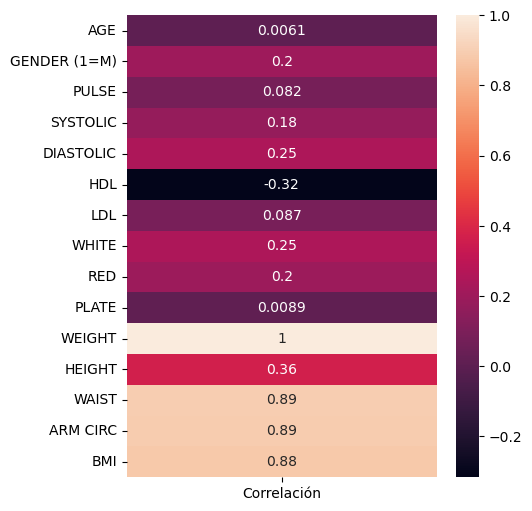

In [20]:
plt.figure(figsize=(5, 6))
sns.heatmap(weight_corr, annot=True)

<Axes: >

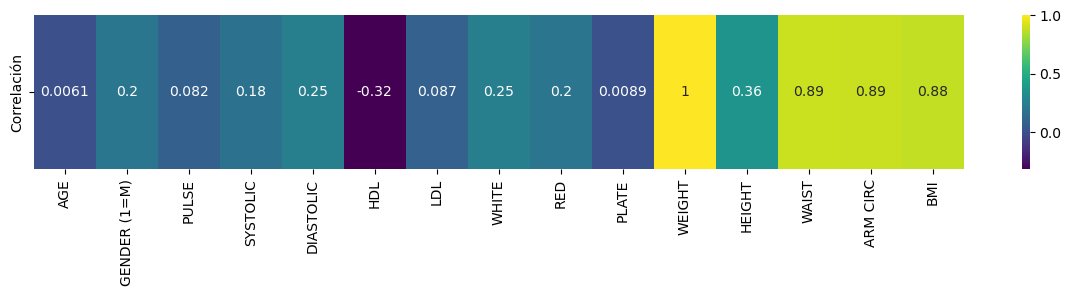

In [21]:
plt.figure(figsize=(15, 2))
sns.heatmap(weight_corr.T, annot=True, cmap='viridis')

# Diagrama de dispersión

Filtrar los registros de los hombres.

In [23]:
h = df[df["GENDER (1=M)"]==1]
h

,AGE,GENDER (1=M),PULSE,SYSTOLIC,DIASTOLIC,HDL,LDL,WHITE,RED,PLATE,WEIGHT,HEIGHT,WAIST,ARM CIRC,BMI
1,57,1,84,112,70,35,116,4.9,4.73,187,96.9,186.0,107.8,37.0,28.0
3,80,1,74,126,64,37,83,7.5,4.32,170,73.1,160.5,97.2,30.3,28.4
4,34,1,50,114,68,50,104,6.1,4.95,140,83.1,179.0,95.1,34.0,25.9
5,77,1,60,134,60,55,75,5.7,3.95,192,86.5,166.7,112.0,31.4,31.1
6,29,1,52,118,64,53,128,4.1,4.68,191,64.1,178.5,78.0,27.4,20.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290,18,1,72,106,44,40,124,4.0,5.17,221,71.6,172.8,78.1,31.0,24.0
292,67,1,62,136,82,39,62,7.7,3.90,305,110.2,169.1,125.5,39.0,38.5
295,24,1,94,96,62,43,102,7.0,5.29,260,56.3,162.7,78.4,27.9,21.3
297,53,1,86,132,74,42,112,8.4,4.07,75,102.6,181.0,117.7,36.5,31.3


Crear un diagrama de dispersión con las variables de interés.

In [ ]:
disp=sns.scatterplot(x=h.BMI

# **Regresión lineal simple**

##Separación de conjunto en atributos y objetivo

Debemos identificar a nuestra variable independiente y a nuestra variable dependiente (variable objetivo).

In [26]:
X = pd.DataFrame(h, columns=['BMI'])
y = h['WEIGHT']
X

,BMI
1,28.0
3,28.4
4,25.9
5,31.1
6,20.1
...,...
290,24.0
292,38.5
295,21.3
297,31.3


In [27]:
y

1       96.9
3       73.1
4       83.1
5       86.5
6       64.1
       ...  
290     71.6
292    110.2
295     56.3
297    102.6
299     56.4
Name: WEIGHT, Length: 153, dtype: float64

Después, separamos nuestro conjunto de datos en el conjunto de prueba y el conjunto de entrenamiento.

Usaremos el 70% de los datos para entrenar a nuestro algoritmo y el 30% para probarlo.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=10)
y_train

182     67.6
70      76.6
112     83.0
271     96.2
131     94.8
       ...  
229    104.8
140     99.5
26      78.5
251    100.4
16      89.5
Name: WEIGHT, Length: 107, dtype: float64

## Cálculo de los coeficientes de la ecuación de regresión lineal

Se utiliza el paquete *LinearRegression* para el cálculo de los coeficientes.

In [31]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()

In [32]:
LR.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [33]:
LR.score(X_train, y_train)

0.837172327182832

In [34]:
pred = LR.predict(X_test)
pred

array([ 83.64958406, 114.23783799,  74.86681808,  88.49524805,
        54.27274614,  80.62104407,  84.86100006,  86.37527006,
        90.00951805,  96.36945203,  87.28383205,  70.92971609,
        71.23257009,  88.49524805,  86.07241606,  82.13531407,
        77.28965008,  93.94662004,  54.87845413,  93.64376604,
        85.16385406, 101.51797002,  75.16967208,  74.26111009,
        58.20984813,  95.76374403,  68.8097381 ,  73.95825609,
       116.66066998,  91.52378804,  78.50106607,  61.54124212,
        81.22675207,  70.92971609, 121.20347997,  83.34673006,
        74.86681808, 100.91226202,  64.56978211, 102.72938601,
        83.64958406,  97.58086803, 110.60358999,  68.5068841 ,
        76.38108808,  76.38108808])

Creamos una tabla para comparar los valores reales y los que el modelo predice.

In [35]:
comparacion = X_test.copy()
comparacion = comparacion.join(y_test)
comparacion['Predicción'] = pred
comparacion

,BMI,WEIGHT,Predicción
193,27.6,89.2,83.649584
124,37.7,126.4,114.237838
162,24.7,73.1,74.866818
198,29.2,95.8,88.495248
151,17.9,50.3,54.272746
208,26.6,77.8,80.621044
224,28.0,89.1,84.861000
19,28.5,86.9,86.375270
93,29.7,90.2,90.009518
257,31.8,104.4,96.369452


Imprimimos el valor del coeficiente B1, que representa la pendiente de la recta.

In [36]:
b1 = LR.coef_
print("Coeficiente b1: \n", b1)

Coeficiente b1: 
 [3.02853999]


Imprimimos el valor del coeficiente B0 que representa la intersección con el eje y.

In [37]:
b0 = LR.intercept_
print("Intersección: \n", b0)

Intersección: 
 0.061880271201715686


Graficamos los datos y la recta obtenida.

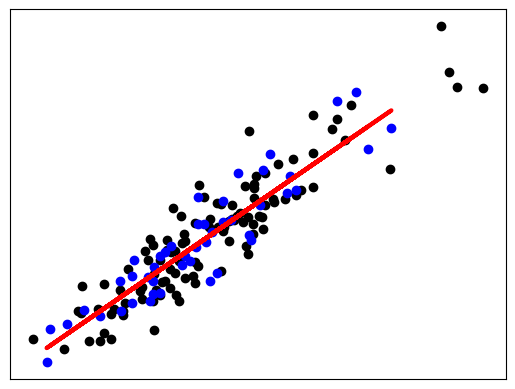

In [38]:
# Plot outputs
plt.scatter(X_train, y_train, color="black")
plt.scatter(X_test, y_test, color="blue")
plt.plot(X_test, pred, color="red", linewidth=3)

plt.xticks(())
plt.yticks(())

plt.show()

Predicción de BMI para un valor específico de altura.

In [47]:
peso = b0 + b1*21
print("El peso de la persona es de: \n", peso)

El peso de la persona es de: 
 [63.66122011]


##Métricas de evaluación

Aquí hay dos métricas de evaluación comunes para problemas de regresión:

**Error cuadrático medio (varianza):** El MSE es la media de los errores cuadráticos:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**R cuadrado:** El valor $$R^2$$ mide la proporción de varianza en la variable objetivo explicada por el modelo. Una puntuación de 1 indica un ajuste perfecto, mientras que una puntuación de 0 indica que el modelo no es mejor que predecir el valor medio de la variable objetivo.

In [48]:
from sklearn import metrics

print('MSE:', metrics.mean_squared_error(y_test, pred))

MSE: 40.438466302073095


In [49]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, pred)
print("R2 score:", r2)

R2 score: 0.857001009282395


# Regresión lineal múltiple

En esta etapa crearemos un modelo de regresión múltiple para calcular el peso usando las variables: estatura, circunferencia de la cintura y circunferencia del brazo.

##Separación de conjunto en atributos y objetivo

Debemos identificar a nuestra variable independiente y a nuestra variable dependiente (variable objetivo).

In [ ]:
# Columnas del df



In [50]:
# Separar la variable objetivo y las variables independientes.
X2 = pd.DataFrame(h, columns=["HEIGHT", "WAIST","ARM CIRC"])
y2 = h["WEIGHT"]
X2

,HEIGHT,WAIST,ARM CIRC
1,186.0,107.8,37.0
3,160.5,97.2,30.3
4,179.0,95.1,34.0
5,166.7,112.0,31.4
6,178.5,78.0,27.4
...,...,...,...
290,172.8,78.1,31.0
292,169.1,125.5,39.0
295,162.7,78.4,27.9
297,181.0,117.7,36.5


In [53]:
y2

1       96.9
3       73.1
4       83.1
5       86.5
6       64.1
       ...  
290     71.6
292    110.2
295     56.3
297    102.6
299     56.4
Name: WEIGHT, Length: 153, dtype: float64

Después, separamos nuestro conjunto de datos en el conjunto de prueba y el conjunto de entrenamiento.

Usaremos el 70% de los datos para entrenar a nuestro algoritmo y el 30% para probarlo.

In [54]:
# Separar en entrenamiento y prueba
from sklearn.model_selection import train_test_split

X2_train, X2_test, y2_train, y2_test = train_test_split(X, y, test_size=0.30, random_state=10)
y2_train

182     67.6
70      76.6
112     83.0
271     96.2
131     94.8
       ...  
229    104.8
140     99.5
26      78.5
251    100.4
16      89.5
Name: WEIGHT, Length: 107, dtype: float64

## Cálculo de los coeficientes de la ecuación de regresión lineal

Se utiliza el paquete *LinearRegression* para el cálculo de los coeficientes.

In [55]:
# Importar el modelo de regresión lineal
from sklearn.model_selection import train_test_split
LR2 = LinearRegression()

In [58]:
# Ajustar a los datos de entrenamiento
LR2.fit(X2_train,y2_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [59]:
# ScoreLR2.fit(X2_train,y2_train)
LR2.score(X2_train,y2_train)

0.837172327182832

Imprimimos el valor de los coeficientes.

In [ ]:
# Imprimir coeficientes


Imprimimos el valor del coeficiente B0 que representa la intersección con el eje y.

In [ ]:
# Imprimir bo


Creamos una tabla para comparar los valores reales y los que el modelo predice.

In [ ]:
comp = X2_test.copy()
comp = comp.join(y2_test)
comp['Predicción'] = pred2
comp

Predicción de BMI para un perfil específico.

In [ ]:
X2.columns

In [ ]:
b12.shape

In [ ]:
peso_m = b02 + b12[0]*183 + b12[1]*105 + b12[2]*35.2
print("El peso de la persona es de: \n", peso_m)

##Métricas de evaluación


In [ ]:
# Calcular el error cuadrático medio


In [ ]:
# Calcular r^2
